# Wheat Disease Classification using EfficientNetV2S

**CropGuard AI: AI-Powered Crop Disease Detection and Advisory System**

Final Year Project, The Islamia University of Bahawalpur (IUB)

| | |
|---|---|
| Students | Muhammad Ali Ejaz, Ahmad Siddique |
| Supervisor | Dr. Faheem Mushtaq |
| Notebook | Wheat model (one of six crop models: wheat, rice, cotton, sugarcane, potato, corn) |

## Overview

This notebook trains the wheat disease classifier used in CropGuard AI. The model takes a photo of a wheat plant and predicts one of 15 classes (14 diseases or pests, plus healthy).

- **Dataset:** Wheat Plant Diseases dataset from Kaggle (`kushagra3204/wheat-plant-diseases`), 14,154 images in 15 classes.
- **Model:** EfficientNetV2S pre-trained on ImageNet, with a small classification head on top.
- **Training:** four phases with progressive unfreezing. The base model is frozen first, then unfrozen and trained with smaller and smaller learning rates.
- **Evaluation:** accuracy, per-class precision/recall/F1, confusion matrix and some sample predictions on the validation set.
- **Output:** the trained model and class files that are used by the CropGuard AI backend.

The notebook was run on Kaggle with a GPU.

## 1. Setup

### 1.1 Libraries

In [1]:
import os
import json
import shutil
import zipfile

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 1.2 Configuration

All paths and main settings are kept in one place so they are easy to change.

In [2]:
# Paths
SOURCE_BASE = "/kaggle/input/datasets/kushagra3204/wheat-plant-diseases/data"
WORKING_BASE = "/kaggle/working/wheat_clean_full"   # cleaned copy of the original train/valid/test folders
DATA_DIR = "/kaggle/working/wheat_all"              # all images merged, one folder per class
OUTPUT_DIR = "/kaggle/working"

# Data settings
IMG_SIZE = (384, 384)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.2
SEED = 42
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

tf.keras.utils.set_random_seed(SEED)

## 2. Dataset Preparation

The dataset already has `train`, `valid` and `test` folders. Before training, three things are done:

1. Copy the dataset to the working directory, because the Kaggle input folder is read-only.
2. Remove images that cannot be decoded.
3. Fix the class folder names in `valid` and `test`. In these two splits the folders have a suffix (for example `mite_test`), so they are renamed to match the `train` names (`Mite`).

In [3]:
# Copy the three splits to a writable location
os.makedirs(WORKING_BASE, exist_ok=True)

for split in ["train", "valid", "test"]:
    dst = os.path.join(WORKING_BASE, split)
    if os.path.exists(dst):
        print(f"{split}/ already copied, skipping")
        continue
    print(f"Copying {split}/ ...")
    shutil.copytree(os.path.join(SOURCE_BASE, split), dst)

Copying train/ ...
Copying valid/ ...
Copying test/ ...


In [4]:
# Remove corrupt images (files that TensorFlow cannot decode)
def remove_corrupt_images(root):
    removed = 0
    for cls in os.listdir(root):
        cls_dir = os.path.join(root, cls)
        if not os.path.isdir(cls_dir):
            continue
        for fname in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, fname)
            try:
                tf.image.decode_image(tf.io.read_file(fpath))
            except Exception:
                os.remove(fpath)
                removed += 1
    return removed


for split in ["train", "valid", "test"]:
    removed = remove_corrupt_images(os.path.join(WORKING_BASE, split))
    print(f"{split}/: removed {removed} corrupt files")

I0000 00:00:1792997714.418307      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792997714.423468      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


train/: removed 0 corrupt files
valid/: removed 0 corrupt files
test/: removed 0 corrupt files


In [5]:
# Make class folder names in valid/ and test/ match the names used in train/
CANONICAL_CLASSES = [
    "Aphid", "Black Rust", "Blast", "Brown Rust", "Common Root Rot",
    "Fusarium Head Blight", "Healthy", "Leaf Blight", "Mildew", "Mite",
    "Septoria", "Smut", "Stem fly", "Tan spot", "Yellow Rust"
]


def normalize(name, split):
    # lower case, drop the split suffix and separators, then compare with the canonical names
    n = name.lower()
    for s in [f"_{split}", "_test", "_valid", "_train"]:
        n = n.replace(s, "")
    n = n.strip("_").replace("_", "").replace(" ", "")
    for c in CANONICAL_CLASSES:
        if c.lower().replace(" ", "") == n:
            return c
    return None


for split in ["valid", "test"]:
    split_dir = os.path.join(WORKING_BASE, split)
    for folder in os.listdir(split_dir):
        canon = normalize(folder, split)
        if canon and folder != canon:
            os.rename(os.path.join(split_dir, folder), os.path.join(split_dir, canon))
            print(f"{split}/: '{folder}' -> '{canon}'")

valid/: 'fusarium_head_blight_valid' -> 'Fusarium Head Blight'
valid/: 'blast_test_valid' -> 'Blast'
valid/: 'black_rust_valid' -> 'Black Rust'
valid/: 'mildew_valid' -> 'Mildew'
valid/: 'healthy_valid' -> 'Healthy'
valid/: 'mite_valid' -> 'Mite'
valid/: 'septoria_valid' -> 'Septoria'
valid/: 'smut_valid' -> 'Smut'
valid/: 'leaf_blight_valid' -> 'Leaf Blight'
valid/: 'yellow_rust_valid' -> 'Yellow Rust'
valid/: 'tan_spot_valid' -> 'Tan spot'
valid/: 'stem_fly_valid' -> 'Stem fly'
valid/: 'common_root_rot_valid' -> 'Common Root Rot'
valid/: 'brown_rust_valid' -> 'Brown Rust'
valid/: 'aphid_valid' -> 'Aphid'
test/: 'black_rust_test' -> 'Black Rust'
test/: 'blast_test' -> 'Blast'
test/: 'yellow_rust_test' -> 'Yellow Rust'
test/: 'tan_spot_test' -> 'Tan spot'
test/: 'septoria_test' -> 'Septoria'
test/: 'common_root_rot_test' -> 'Common Root Rot'
test/: 'leaf_blight_test' -> 'Leaf Blight'
test/: 'healthy_test' -> 'Healthy'
test/: 'mildew_test' -> 'Mildew'
test/: 'stem_fly_test' -> 'Stem fly

### 2.1 Merging the splits

The three original splits are merged into one folder per class and then split again with a proper 80/20 train/validation split (done in the next section). The split name is added as a prefix to each file name so that files from different splits never overwrite each other.

In [6]:
os.makedirs(DATA_DIR, exist_ok=True)

for split in ["train", "valid", "test"]:
    split_dir = os.path.join(WORKING_BASE, split)
    for cls in os.listdir(split_dir):
        cls_src = os.path.join(split_dir, cls)
        cls_dst = os.path.join(DATA_DIR, cls)
        if not os.path.isdir(cls_src):
            continue
        os.makedirs(cls_dst, exist_ok=True)
        for fname in os.listdir(cls_src):
            dst = os.path.join(cls_dst, f"{split}_{fname}")
            if not os.path.exists(dst):
                shutil.copy2(os.path.join(cls_src, fname), dst)

### 2.2 Class distribution

Aphid: 973
Black Rust: 646
Blast: 717
Brown Rust: 1341
Common Root Rot: 684
Fusarium Head Blight: 681
Healthy: 1070
Leaf Blight: 912
Mildew: 1151
Mite: 870
Septoria: 1214
Smut: 1380
Stem fly: 304
Tan spot: 840
Yellow Rust: 1371

Total: 14154 images in 15 classes


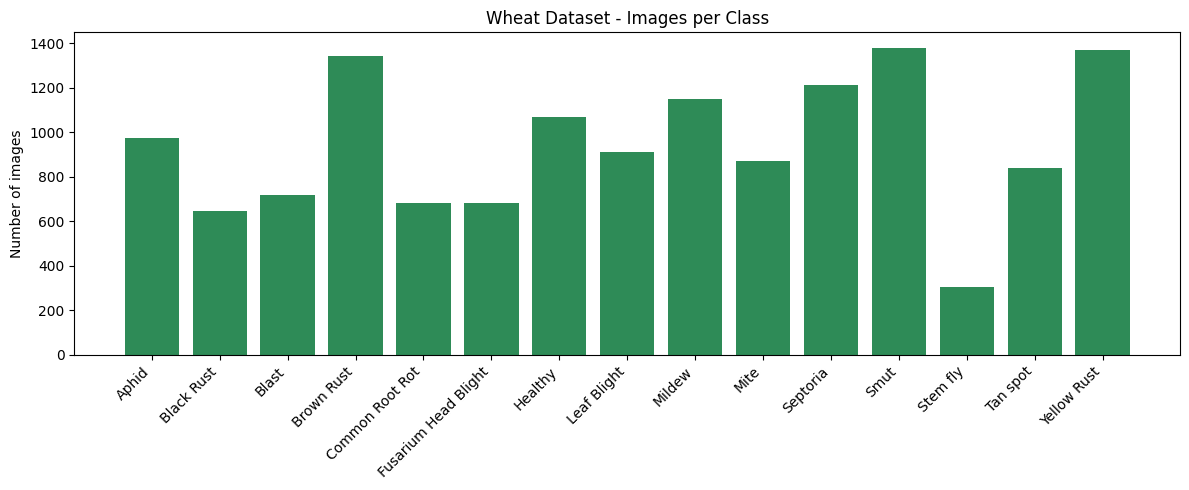

In [7]:
def count_images(folder):
    return len([f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTENSIONS)])


class_counts = {cls: count_images(os.path.join(DATA_DIR, cls)) for cls in sorted(os.listdir(DATA_DIR))}

for cls, n in class_counts.items():
    print(f"{cls}: {n}")
print(f"\nTotal: {sum(class_counts.values())} images in {len(class_counts)} classes")

plt.figure(figsize=(12, 5))
plt.bar(class_counts.keys(), class_counts.values(), color="seagreen")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Wheat Dataset - Images per Class")
plt.tight_layout()
plt.show()

The classes are not perfectly balanced. Stem fly has far fewer images (304) than the other classes, so class weights are used during training (section 4).

## 3. Loading the Data

`image_dataset_from_directory` reads the images from the merged folder and splits them 80% for training and 20% for validation. The same seed is used for both calls so the two subsets do not overlap.

In [8]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=VALIDATION_SPLIT,
    subset="training", seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=VALIDATION_SPLIT,
    subset="validation", seed=SEED
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Found 14154 files belonging to 15 classes.
Using 11324 files for training.
Found 14154 files belonging to 15 classes.
Using 2830 files for validation.
Classes: ['Aphid', 'Black Rust', 'Blast', 'Brown Rust', 'Common Root Rot', 'Fusarium Head Blight', 'Healthy', 'Leaf Blight', 'Mildew', 'Mite', 'Septoria', 'Smut', 'Stem fly', 'Tan spot', 'Yellow Rust']
Number of classes: 15


## 4. Class Weights

Because of the class imbalance, each class gets a weight that is higher for smaller classes. This makes mistakes on rare classes (like Stem fly) cost more during training.

In [9]:
labels_flat = []
for i, cls in enumerate(class_names):
    labels_flat.extend([i] * count_images(os.path.join(DATA_DIR, cls)))
labels_flat = np.array(labels_flat)

cw_values = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw_values)}

for i, cls in enumerate(class_names):
    print(f"{cls}: {class_weight_dict[i]:.3f}")

Aphid: 0.970
Black Rust: 1.461
Blast: 1.316
Brown Rust: 0.704
Common Root Rot: 1.380
Fusarium Head Blight: 1.386
Healthy: 0.882
Leaf Blight: 1.035
Mildew: 0.820
Mite: 1.085
Septoria: 0.777
Smut: 0.684
Stem fly: 3.104
Tan spot: 1.123
Yellow Rust: 0.688


## 5. Augmentation and Preprocessing

Random flips, rotation, zoom, brightness and contrast are applied to the training images only. This helps the model handle different camera angles and lighting. The validation images are only preprocessed, not augmented, so the validation score stays consistent.

In [10]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
])


def prep_train(img, lbl):
    return preprocess_input(augmentation(img)), lbl


def prep_val(img, lbl):
    return preprocess_input(img), lbl


train_ds_p = train_ds.map(prep_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_p = val_ds.map(prep_val, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

## 6. Model

EfficientNetV2S is used as the base model with ImageNet weights and without its original top layer. On top of it we add:

- Global average pooling to turn the feature maps into one vector
- Batch normalization
- Dropout (0.4) to reduce overfitting
- A dense softmax layer with one output per class

The base model starts frozen so that only the new head is trained in the first phase.

In [11]:
base = EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(384, 384, 3))
base.trainable = False

inputs = keras.Input(shape=(384, 384, 3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.summary()

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 12, 12, 1280)   │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,355,695 (77.65 MB)

 Trainable params: 21,775 (85.06 KB)

 Non-trainable params: 20,333,920 (77.57 MB)

### 6.1 Callbacks

- **EarlyStopping:** stops a phase when validation accuracy stops improving and goes back to the best weights.
- **ModelCheckpoint:** saves the model with the best validation accuracy to `wheat_best.keras`.
- **ReduceLROnPlateau:** lowers the learning rate when validation loss stops improving.
- **BackupAndRestore:** saves training progress so a crashed session can continue.

The same list is used for phases 1 to 3. Phase 4 gets its own list with more patience.

In [12]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f"{OUTPUT_DIR}/wheat_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    keras.callbacks.BackupAndRestore(f"{OUTPUT_DIR}/backup/")
]

## 7. Training

Training is done in four phases. The learning rate gets smaller in every phase, so the pre-trained weights are changed gently once the base model is unfrozen.

| Phase | Base model | Learning rate | Max epochs |
|---|---|---|---|
| 1 | Frozen | 1e-3 | 10 |
| 2 | Fully unfrozen | 1e-4 | 10 |
| 3 | Fully unfrozen | 5e-5 | 15 |
| 4 | Fully unfrozen (best weights reloaded) | 1e-5 | 15 |

### Phase 1: Frozen base

Only the new classification head is trained. This gives the head sensible weights before the base model is touched.

In [13]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])

h1 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 1 best validation accuracy: {max(h1.history['val_accuracy']) * 100:.2f}%")

Epoch 1/10


2026-10-26 06:58:58.034663: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 06:58:58.204319: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 06:58:59.334240: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 06:58:59.514716: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 06:59:01.216652: E external/local_xla/xla/stream_

353/354 ━━━━━━━━━━━━━━━━━━━━ 0s 654ms/step - accuracy: 0.4211 - loss: 2.1131

2026-10-26 07:03:23.698852: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:03:23.864145: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:03:25.052877: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:03:25.228414: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:03:26.903377: E external/local_xla/xla/stream_

354/354 ━━━━━━━━━━━━━━━━━━━━ 0s 752ms/step - accuracy: 0.4214 - loss: 2.1119

2026-10-26 07:04:28.658145: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:04:28.803302: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:04:29.742573: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:04:29.892851: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:04:31.433905: E external/local_xla/xla/stream_

354/354 ━━━━━━━━━━━━━━━━━━━━ 388s 910ms/step - accuracy: 0.5238 - loss: 1.6585 - val_accuracy: 0.7134 - val_loss: 0.9099 - learning_rate: 0.0010
Epoch 2/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 262s 734ms/step - accuracy: 0.6424 - loss: 1.1830 - val_accuracy: 0.7375 - val_loss: 0.7996 - learning_rate: 0.0010
Epoch 3/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 260s 728ms/step - accuracy: 0.6766 - loss: 1.0543 - val_accuracy: 0.7300 - val_loss: 0.8238 - learning_rate: 0.0010
Epoch 4/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 259s 725ms/step - accuracy: 0.6822 - loss: 1.0269 - val_accuracy: 0.7601 - val_loss: 0.7476 - learning_rate: 0.0010
Epoch 5/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 258s 723ms/step - accuracy: 0.6928 - loss: 0.9945 - val_accuracy: 0.7428 - val_loss: 0.7810 - learning_rate: 0.0010
Epoch 6/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 261s 733ms/step - accuracy: 0.7043 - loss: 0.9547 - val_accuracy: 0.7505 - val_loss: 0.7333 - learning_rate: 0.0010
Epoch 7/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 257s 720ms/step - accuracy: 0.6994 

### Phase 2: Full fine-tuning (lr = 1e-4)

The whole base model is unfrozen so the pre-trained features can adapt to wheat leaves.

In [14]:
base.trainable = True

model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])

h2 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 2 best validation accuracy: {max(h2.history['val_accuracy']) * 100:.2f}%")

Epoch 1/10


2026-10-26 07:45:14.144563: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:45:14.330798: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:45:19.295984: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:45:19.474286: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:45:21.515127: E external/local_xla/xla/stream_

353/354 ━━━━━━━━━━━━━━━━━━━━ 0s 890ms/step - accuracy: 0.6425 - loss: 1.2463

2026-10-26 07:51:59.996971: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:52:00.175639: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:52:04.578281: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:52:04.756071: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 07:52:06.602025: E external/local_xla/xla/stream_

354/354 ━━━━━━━━━━━━━━━━━━━━ 624s 1s/step - accuracy: 0.7038 - loss: 1.0071 - val_accuracy: 0.8166 - val_loss: 0.5812 - learning_rate: 1.0000e-04
Epoch 2/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 343s 963ms/step - accuracy: 0.8000 - loss: 0.6120 - val_accuracy: 0.8466 - val_loss: 0.4683 - learning_rate: 1.0000e-04
Epoch 3/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 383s 966ms/step - accuracy: 0.8509 - loss: 0.4535 - val_accuracy: 0.8625 - val_loss: 0.4182 - learning_rate: 1.0000e-04
Epoch 4/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 336s 942ms/step - accuracy: 0.8717 - loss: 0.3832 - val_accuracy: 0.8813 - val_loss: 0.3795 - learning_rate: 1.0000e-04
Epoch 5/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 342s 960ms/step - accuracy: 0.8984 - loss: 0.3091 - val_accuracy: 0.8841 - val_loss: 0.3905 - learning_rate: 1.0000e-04
Epoch 6/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 516s 1s/step - accuracy: 0.9025 - loss: 0.2679 - val_accuracy: 0.8799 - val_loss: 0.4168 - learning_rate: 1.0000e-04
Epoch 7/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 343s 963ms/step -

### Phase 3: Full fine-tuning (lr = 5e-5)

Training continues with a smaller learning rate for finer updates.

In [15]:
model.compile(optimizer=keras.optimizers.Adam(5e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

h3 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 3 best validation accuracy: {max(h3.history['val_accuracy']) * 100:.2f}%")

Epoch 1/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 585s 1s/step - accuracy: 0.9365 - loss: 0.1666 - val_accuracy: 0.8933 - val_loss: 0.3701 - learning_rate: 5.0000e-05
Epoch 2/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 342s 959ms/step - accuracy: 0.9418 - loss: 0.1493 - val_accuracy: 0.8975 - val_loss: 0.3900 - learning_rate: 5.0000e-05
Epoch 3/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 342s 960ms/step - accuracy: 0.9528 - loss: 0.1246 - val_accuracy: 0.8989 - val_loss: 0.3864 - learning_rate: 1.5000e-05
Epoch 4/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 342s 959ms/step - accuracy: 0.9600 - loss: 0.1041 - val_accuracy: 0.9004 - val_loss: 0.3825 - learning_rate: 1.5000e-05
Epoch 5/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 512s 1s/step - accuracy: 0.9573 - loss: 0.1082 - val_accuracy: 0.9014 - val_loss: 0.3866 - learning_rate: 4.5000e-06
Epoch 6/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 342s 958ms/step - accuracy: 0.9590 - loss: 0.0993 - val_accuracy: 0.9032 - val_loss: 0.3863 - learning_rate: 4.5000e-06
Epoch 7/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 494s 1

### Phase 4: Final polish (lr = 1e-5)

The best weights saved so far are loaded again and trained with a very small learning rate and more patience, to squeeze out the last bit of accuracy.

In [16]:
model.load_weights(f"{OUTPUT_DIR}/wheat_best.keras")

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

callbacks_p4 = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f"{OUTPUT_DIR}/wheat_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-8),
    keras.callbacks.BackupAndRestore(f"{OUTPUT_DIR}/backup/")
]

h4 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks_p4)

print(f"Phase 4 best validation accuracy: {max(h4.history['val_accuracy']) * 100:.2f}%")

Epoch 1/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 750s 2s/step - accuracy: 0.9595 - loss: 0.1051 - val_accuracy: 0.9014 - val_loss: 0.3928 - learning_rate: 1.0000e-05
Epoch 2/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 340s 954ms/step - accuracy: 0.9608 - loss: 0.1005 - val_accuracy: 0.9004 - val_loss: 0.3886 - learning_rate: 1.0000e-05
Epoch 3/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 385s 961ms/step - accuracy: 0.9622 - loss: 0.0976 - val_accuracy: 0.9021 - val_loss: 0.3910 - learning_rate: 1.0000e-05
Epoch 4/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 379s 954ms/step - accuracy: 0.9638 - loss: 0.0961 - val_accuracy: 0.8996 - val_loss: 0.3950 - learning_rate: 1.0000e-05
Epoch 5/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 381s 951ms/step - accuracy: 0.9631 - loss: 0.0920 - val_accuracy: 0.9039 - val_loss: 0.3967 - learning_rate: 1.0000e-05
Epoch 6/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 515s 1s/step - accuracy: 0.9638 - loss: 0.0872 - val_accuracy: 0.9000 - val_loss: 0.4048 - learning_rate: 3.0000e-06
Epoch 7/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 340s 9

### 7.1 Training curves

The plots below join all four phases. The dashed vertical lines show where a new phase starts.

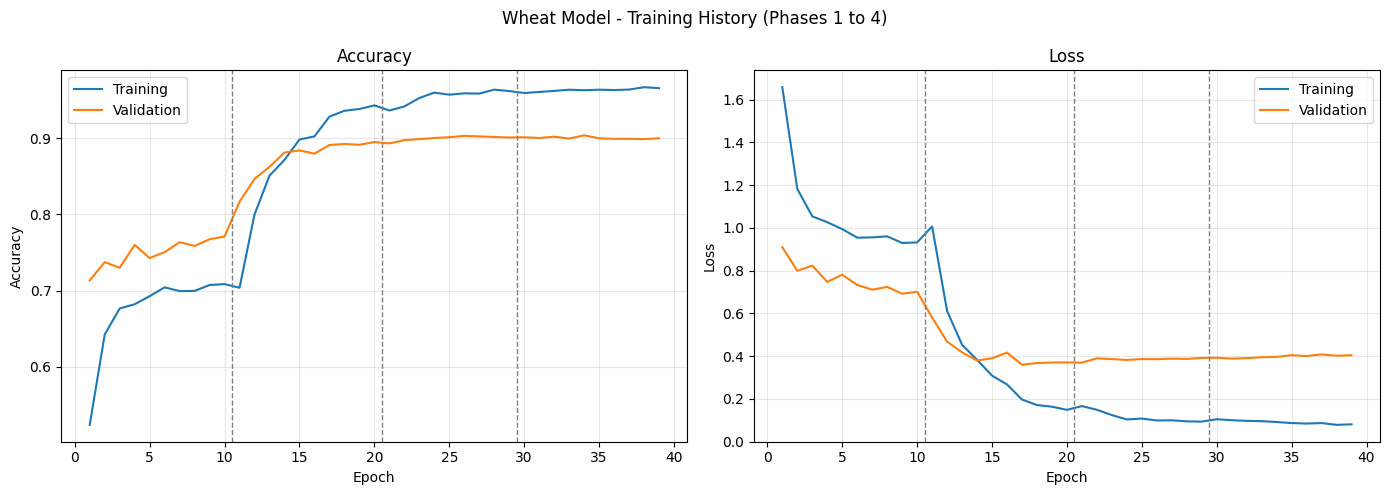

In [17]:
histories = [h1, h2, h3, h4]

train_acc, val_acc, train_loss, val_loss = [], [], [], []
phase_ends = []
for h in histories:
    train_acc += h.history["accuracy"]
    val_acc += h.history["val_accuracy"]
    train_loss += h.history["loss"]
    val_loss += h.history["val_loss"]
    phase_ends.append(len(train_acc))

epochs_range = range(1, len(train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, train_acc, label="Training")
axes[0].plot(epochs_range, val_acc, label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].plot(epochs_range, train_loss, label="Training")
axes[1].plot(epochs_range, val_loss, label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")

for ax in axes:
    for end in phase_ends[:-1]:
        ax.axvline(end + 0.5, color="gray", linestyle="--", linewidth=1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Wheat Model - Training History (Phases 1 to 4)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/wheat_training_curves.png", dpi=150)
plt.show()

## 8. Evaluation

The model is evaluated on the validation set (20% of the images, never used for weight updates). Precision, recall and F1-score are reported for every class, followed by the confusion matrix.

In [18]:
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

val_accuracy = np.mean(y_true == y_pred)
print(f"Validation accuracy: {val_accuracy * 100:.2f}%  ({len(y_true)} images)\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

Validation accuracy: 90.39%  (2830 images)

                      precision    recall  f1-score   support

               Aphid     0.8950    0.9372    0.9156       191
          Black Rust     0.7574    0.8655    0.8078       119
               Blast     0.9062    0.8467    0.8755       137
          Brown Rust     0.9077    0.8708    0.8889       271
     Common Root Rot     0.8729    0.8240    0.8477       125
Fusarium Head Blight     0.9699    0.9847    0.9773       131
             Healthy     0.9636    0.9860    0.9747       215
         Leaf Blight     0.7283    0.7128    0.7204       188
              Mildew     0.9793    0.9672    0.9732       244
                Mite     0.8659    0.8712    0.8685       163
            Septoria     0.9696    0.9253    0.9469       241
                Smut     0.9695    0.9630    0.9662       297
            Stem fly     0.9688    0.9841    0.9764        63
            Tan spot     0.6529    0.7161    0.6831       155
         Yellow Rust     

The classification report shows how well each class is predicted. Classes with lower scores are usually the ones with symptoms that look similar to other classes, and the confusion matrix below shows which classes get mixed up.

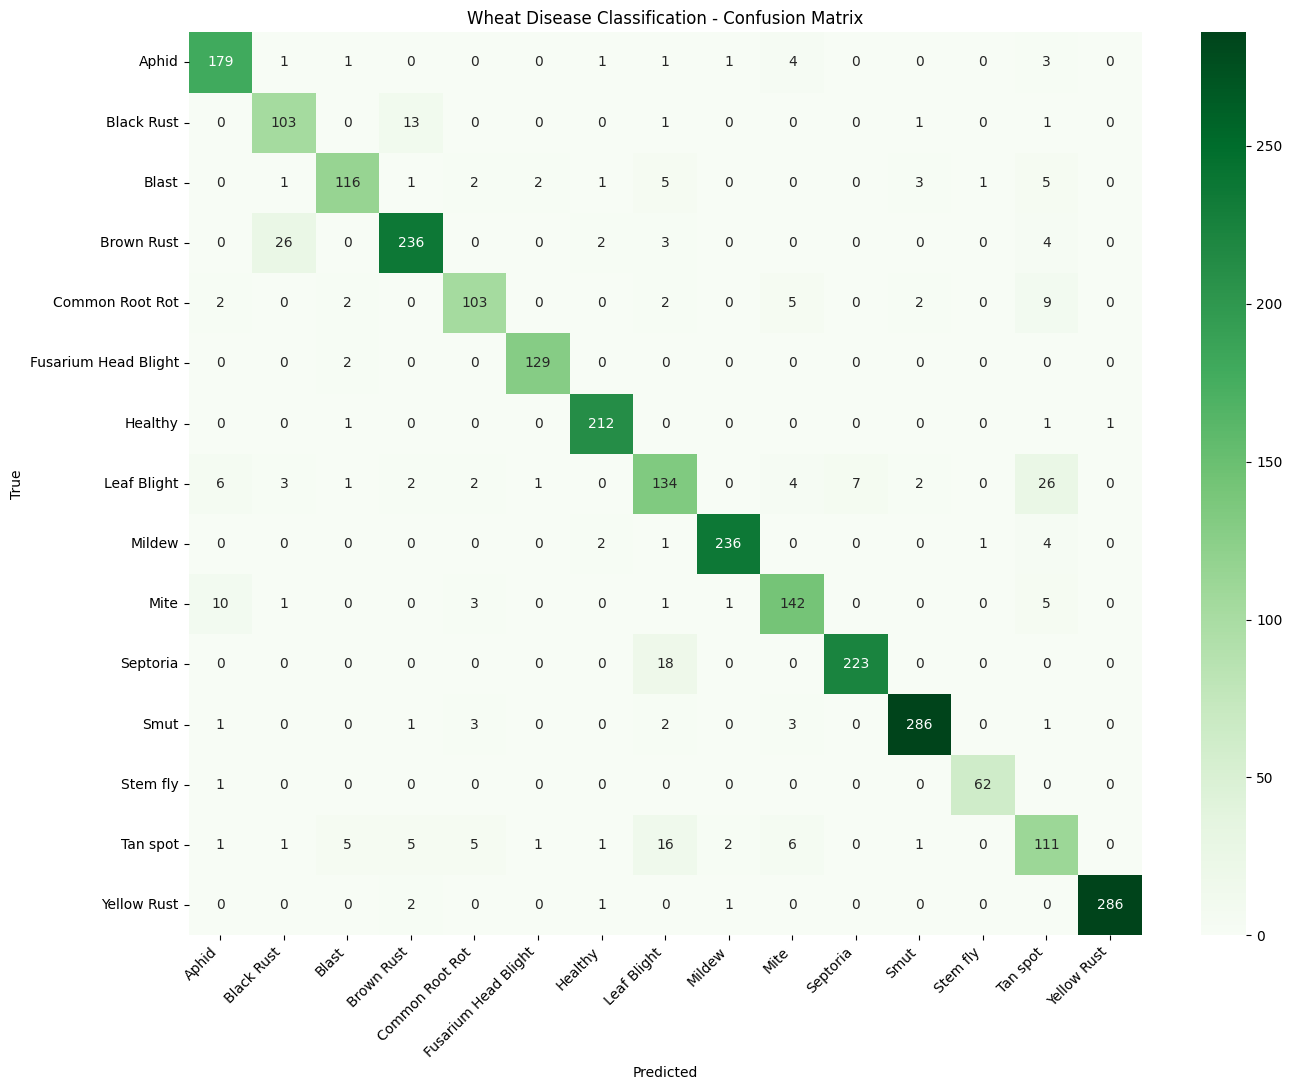

In [19]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Wheat Disease Classification - Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/wheat_confusion_matrix.png", dpi=150)
plt.show()

### 8.1 Sample predictions

A batch of validation images with the true label, the predicted label and the model's confidence. Green titles are correct predictions and red titles are mistakes.

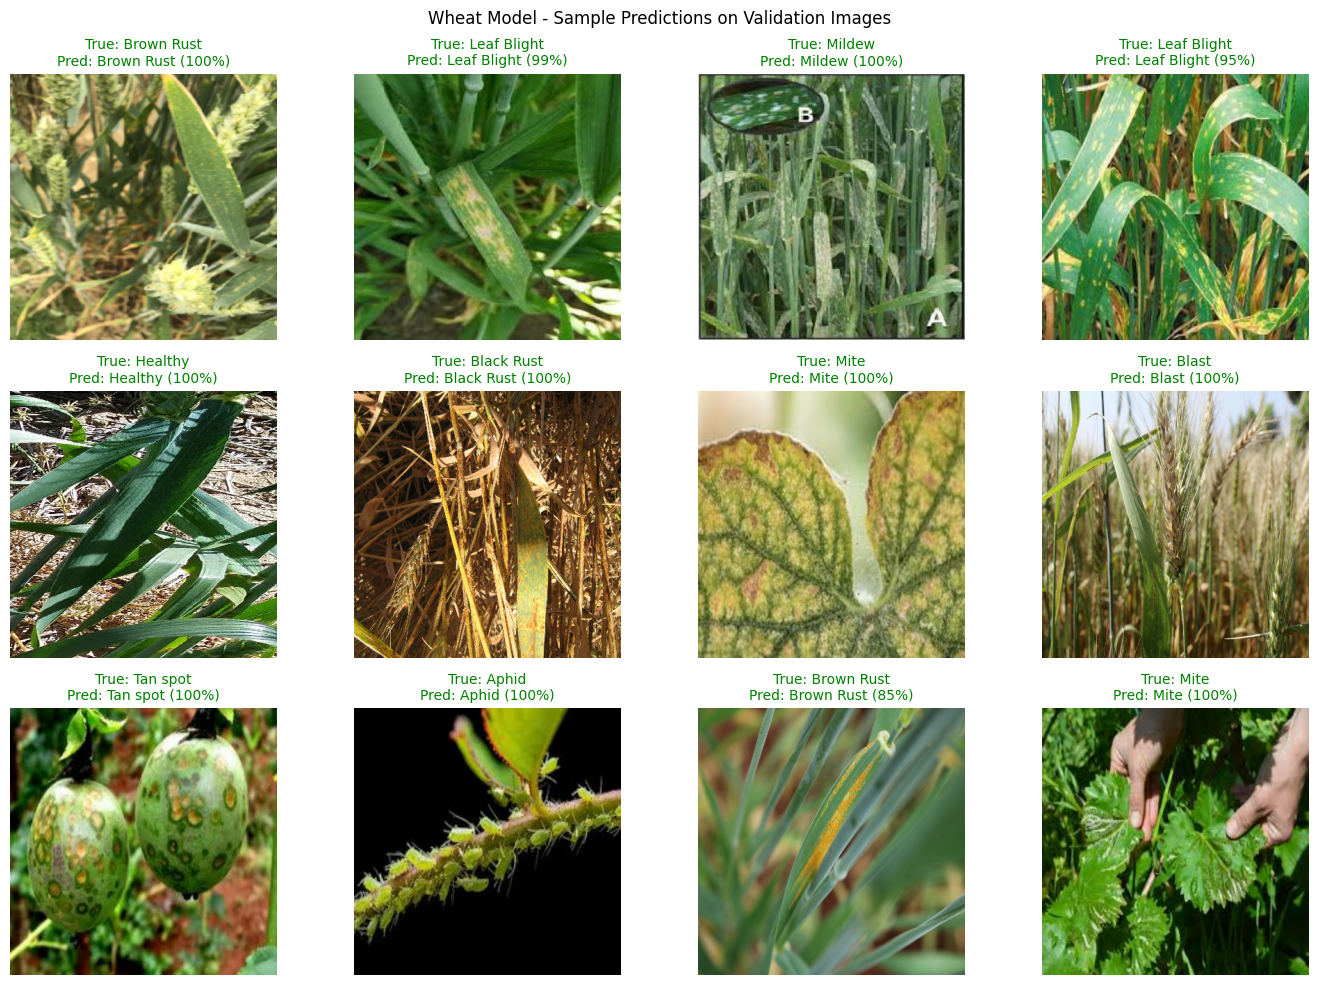

In [20]:
sample_images, sample_labels = next(iter(val_ds))
sample_probs = model.predict(preprocess_input(sample_images), verbose=0)

sample_true = np.argmax(sample_labels.numpy(), axis=1)
sample_pred = np.argmax(sample_probs, axis=1)

plt.figure(figsize=(14, 10))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_images[i].numpy().astype("uint8"))
    plt.axis("off")

    confidence = sample_probs[i][sample_pred[i]] * 100
    correct = sample_true[i] == sample_pred[i]
    plt.title(f"True: {class_names[sample_true[i]]}\nPred: {class_names[sample_pred[i]]} ({confidence:.0f}%)",
              fontsize=10, color="green" if correct else "red")

plt.suptitle("Wheat Model - Sample Predictions on Validation Images")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/wheat_sample_predictions.png", dpi=150)
plt.show()

## 9. Saving the Model

The final model is saved together with two JSON files that the CropGuard AI backend needs:

- `wheat_class_names.json`: the class labels in the same order as the model outputs, in the form `wheat__<disease>`
- `wheat_class_map.json`: maps each label to the crop name and a readable disease name

Everything is then packed into one zip file.

In [21]:
model.save(f"{OUTPUT_DIR}/wheat_final.keras")
size_mb = os.path.getsize(f"{OUTPUT_DIR}/wheat_final.keras") / 1024 / 1024
print(f"Model saved ({size_mb:.1f} MB)")

Model saved (233.8 MB)


In [22]:
wheat_class_map = {}
production_class_names = []

for cls in class_names:
    key = "wheat__" + cls.lower().replace(" ", "_")
    production_class_names.append(key)
    wheat_class_map[key] = {"crop": "Wheat", "disease": cls.title()}

with open(f"{OUTPUT_DIR}/wheat_class_map.json", "w") as f:
    json.dump(wheat_class_map, f, indent=2)
with open(f"{OUTPUT_DIR}/wheat_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)

print(json.dumps(wheat_class_map, indent=2))

{
  "wheat__aphid": {
    "crop": "Wheat",
    "disease": "Aphid"
  },
  "wheat__black_rust": {
    "crop": "Wheat",
    "disease": "Black Rust"
  },
  "wheat__blast": {
    "crop": "Wheat",
    "disease": "Blast"
  },
  "wheat__brown_rust": {
    "crop": "Wheat",
    "disease": "Brown Rust"
  },
  "wheat__common_root_rot": {
    "crop": "Wheat",
    "disease": "Common Root Rot"
  },
  "wheat__fusarium_head_blight": {
    "crop": "Wheat",
    "disease": "Fusarium Head Blight"
  },
  "wheat__healthy": {
    "crop": "Wheat",
    "disease": "Healthy"
  },
  "wheat__leaf_blight": {
    "crop": "Wheat",
    "disease": "Leaf Blight"
  },
  "wheat__mildew": {
    "crop": "Wheat",
    "disease": "Mildew"
  },
  "wheat__mite": {
    "crop": "Wheat",
    "disease": "Mite"
  },
  "wheat__septoria": {
    "crop": "Wheat",
    "disease": "Septoria"
  },
  "wheat__smut": {
    "crop": "Wheat",
    "disease": "Smut"
  },
  "wheat__stem_fly": {
    "crop": "Wheat",
    "disease": "Stem Fly"
  },
  "wh

In [23]:
files = [
    f"{OUTPUT_DIR}/wheat_final.keras",
    f"{OUTPUT_DIR}/wheat_best.keras",
    f"{OUTPUT_DIR}/wheat_class_map.json",
    f"{OUTPUT_DIR}/wheat_class_names.json",
    f"{OUTPUT_DIR}/wheat_confusion_matrix.png",
    f"{OUTPUT_DIR}/wheat_training_curves.png",
    f"{OUTPUT_DIR}/wheat_sample_predictions.png",
]

zip_path = f"{OUTPUT_DIR}/wheat_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
            print(f"added {os.path.basename(f)} ({os.path.getsize(f) / 1024 / 1024:.1f} MB)")
        else:
            print(f"missing: {f}")

print(f"\nPackage: {zip_path} ({os.path.getsize(zip_path) / 1024 / 1024:.1f} MB)")

added wheat_final.keras (233.8 MB)
added wheat_best.keras (233.8 MB)
added wheat_class_map.json (0.0 MB)
added wheat_class_names.json (0.0 MB)
added wheat_confusion_matrix.png (0.2 MB)
added wheat_training_curves.png (0.1 MB)
added wheat_sample_predictions.png (3.4 MB)

Package: /kaggle/working/wheat_model_package.zip (471.3 MB)


## 10. Summary and Limitations

**Summary**

- An EfficientNetV2S model was fine-tuned on 14,154 wheat images from 15 classes using four training phases with decreasing learning rates.
- Class weights were used to handle the imbalance between classes, and augmentation was applied to the training images only.
- The final validation accuracy, per-class scores, confusion matrix, and sample predictions are shown in section 8.
- The saved model and class files are used in the CropGuard AI website and mobile app.

**Limitations**

- The reported accuracy is validation accuracy. The same validation set was used for early stopping and for choosing the best checkpoint, so the score can be slightly higher than what a completely unseen test set would give.
- The original train, valid and test folders were merged and split again randomly. If the dataset contains very similar images (for example several photos of the same plant), some of them can end up in both training and validation, which can make the accuracy look better than it really is.
- The images may be different from photos that farmers take with their phones in the field (lighting, background, camera quality), so accuracy in real use can be lower.

**Future work**

- Test the model on a separate set of wheat images collected from fields in Pakistan.
- Collect more images for the classes with the lowest scores.